In [45]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn

print("numpy", np.__version__)
print("matplotlib", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)

numpy 2.5.4
matplotlib 3.11.2
scikit-learn 1.9.1


In [46]:
# Plot styling
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 110

rng = np.random.default_rng(seed=0)

In [47]:
a = np.array([1.0, 2.0, 3.0]) # 1D: a vector of 3 numbers
b = np.array(
    [
        [1.0, 2.0, 3.0],  # 2D: 2 rows, 3 columns
        [4.0, 5.0 ,6.0],
    ]
)

print("a = ", a)
print("a.shape = ", a.shape)  # (3,) -> 1D, length 3
print()
print("b = ")
print(b)
print("b.shape =", b.shape)  # (2, 3) -> 2 rows, 3 columns

a =  [1. 2. 3.]
a.shape =  (3,)

b = 
[[1. 2. 3.]
 [4. 5. 6.]]
b.shape = (2, 3)


In [48]:
row = np.array([[1.0, 2.0, 3.0]]) # note the double brackets
col = np.array([[1.0], [2.0], [3.0]])

print("a shape", a.shape, " <- 1D, no orientation")
print("row shape", row.shape, "<- 2D, one row")
print("col shape", col.shape, "<- 2D, one column")

# reshape(-1, 1) is the idiom for "make this a single column".
# The -1 means "work out the size for me".
print()
print("a.reshape(-1, 1) shape:", a.reshape(-1, 1).shape)

a shape (3,)  <- 1D, no orientation
row shape (1, 3) <- 2D, one row
col shape (3, 1) <- 2D, one column

a.reshape(-1, 1) shape: (3, 1)


In [49]:
import time

big = rng.normal(size=20000000)

t0 = time.perf_counter()
result_loop = [v ** 2 for v in big]  # the python way
t1 = time.perf_counter()
result_vec = big ** 2 # the numpy way
t2 = time.perf_counter()

print(f"Python loop : {t1 - t0:.4f} s")
print(f"NumPy       : {t2 - t1:.4f} s")
print(f"speed-up    : {(t1 - t0) / (t2 - t1):.0f}x")

Python loop : 0.9421 s
NumPy       : 0.0032 s
speed-up    : 297x


## 1.3 Matrix multiplication — the `@` operator

This is the operation at the heart of every neural network, so it is worth a minute.

Matrix multiplication combines two arrays by taking **rows of the first against
columns of the second**. For each output entry, you multiply the matching numbers
pairwise and add them up.

The shape rule is the only thing you have to remember:

```
(n, k) @ (k, m)  ->  (n, m)
      ^^^^^^^  these must match; they cancel out
```

The inner numbers must be equal, and they disappear from the result.

In [50]:
A_ = np.array([[1.0, 2.0], 
               [3.0, 4.0], 
               [5.0, 6.0]])  # (3, 2)

B_ = np.array([[10.0, 20.0, 30.0, 40.0], 
               [50.0, 60.0, 70.0, 80.0]])  # (2, 4)

C_ = A_ @ B_

print("A_ shape", A_.shape)
print("B_ shape", B_.shape)
print("C_ shape", C_.shape, " <- (3, 2) @ (2, 4) -> (3, 4)")
print()
print(C_)

A_ shape (3, 2)
B_ shape (2, 4)
C_ shape (3, 4)  <- (3, 2) @ (2, 4) -> (3, 4)

[[110. 140. 170. 200.]
 [230. 300. 370. 440.]
 [350. 460. 570. 680.]]


In [51]:
X = rng.normal(size=(5, 2))  # 5 examples, 2 features
W = rng.normal(size=(2, 3))  # 2 features in, 3 units out

Z = X @ W
print("X", X.shape, "@ W", W.shape, "-> Z", Z.shape)

X (5, 2) @ W (2, 3) -> Z (5, 3)


---
# Part 2 — A single neuron

A neuron is a small function. It takes some numbers in, and puts one number out. It
does this in two steps:

**Step 1 — weighted sum.** Multiply each input by a *weight*, add them up, then add a
*bias*:

$$z = x_1 w_1 + x_2 w_2 + \dots + b$$

The weights say how much each input matters. A large positive weight means "this
input pushes the answer up"; a large negative weight means "this input pushes it
down"; a weight near zero means "ignore this input". The bias shifts the whole thing
up or down regardless of the inputs.

**Step 2 — activation.** Pass `z` through a squashing function `a = f(z)`.

The weights and the bias are the **parameters** — the numbers that get *learned*.
Everything else about the network is fixed by us in advance.

In [52]:
def neuron(x, w, b):
    """
    x: inputs
    w: weights
    b: bias
    """
    return x @ w + b

x = np.array([2.0, 3.0])  # one example with two features
w = np.array([0.5, -1.0])  # its two weights
b = 1.0

print("z =", neuron(x, w, b))
print("by hand:", 2.0 * 0.5 + 3.0 * -1.0 + 1.0)

z = -1.0
by hand: -1.0


## 2.1 Activation functions

Why not stop at the weighted sum? Because a weighted sum is a *straight line*, and
stacking straight lines on top of straight lines only ever gives you another straight
line. Without a non-linear activation function, a hundred-layer network can do no
more than a single layer can. (We will demonstrate this dramatically in notebook 2.)

The activation function bends the line. Two of them cover most of what you'll meet:

**Sigmoid** squashes anything into the range 0 to 1, which makes it readable as a
probability. Large positive input → near 1. Large negative → near 0. Zero → exactly
0.5.

**ReLU** ("rectified linear unit") is almost embarrassingly simple: negatives become
zero, positives pass through unchanged. It is the default inside modern networks
because it is fast and trains well.

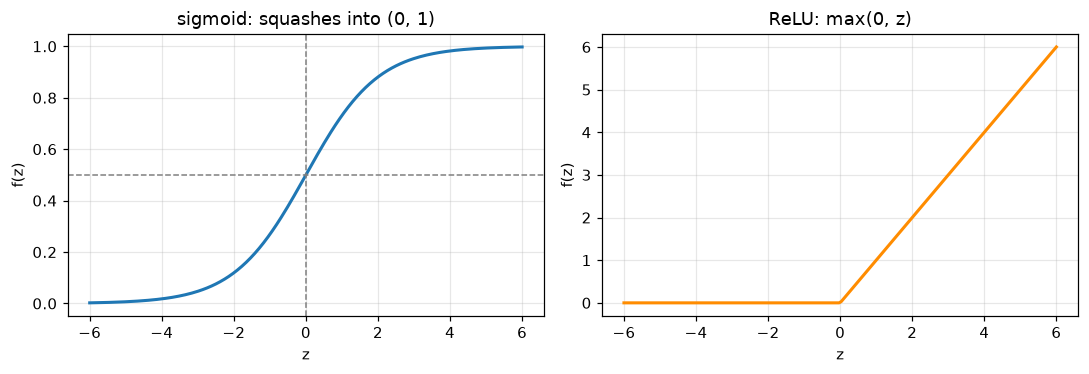

In [53]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def relu(z):
    return np.maximum(0.0, z)

zs = np.linspace(-6, 6, 200)  # 200 evenly spaced values from -6 to 6

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(zs, sigmoid(zs), linewidth=2)
axes[0].axhline(0.5, linestyle="--", linewidth=1, color="gray")
axes[0].axvline(0.0, linestyle="--", linewidth=1, color="gray")
axes[0].set_title("sigmoid: squashes into (0, 1)")
axes[0].set_xlabel("z")
axes[0].set_ylabel("f(z)")

axes[1].plot(zs, relu(zs), linewidth=2, color="darkorange")
axes[1].set_title("ReLU: max(0, z)")
axes[1].set_xlabel("z")
axes[1].set_ylabel("f(z)")

plt.tight_layout()
plt.show()

## 2.2 A neuron is a line

Here's the geometric picture:

With two input features, the neuron computes `z = x1*w1 + x2*w2 + b`. The set of
points where `z = 0` is a **straight line** on the plane. On one side `z` is
positive, on the other it's negative. Push `z` through sigmoid and you get: "above
0.5 on one side, below 0.5 on the other".

So **one neuron splits the plane with a straight line**. The weights control the
line's angle; the bias slides it back and forth.

Let's see that. First we need some data.

X (200, 2)  y (200,)
labels present: [0 1]


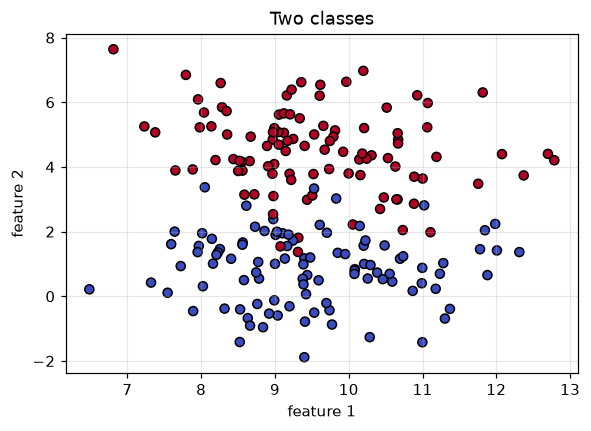

In [54]:
from sklearn.datasets import make_blobs

# Two clearly separated clusters, 2 features each
X, y = make_blobs(
    n_samples=200, centers=2, n_features=2, cluster_std=1.2, random_state=4
)

print("X", X.shape, " y", y.shape)
print("labels present:", np.unique(y))

plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=35)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two classes")
plt.show()

In [55]:
def plot_decision_boundary(predict_fn, X, y, title="", ax=None):
    """Shade the plane by what predict_fn says, then scatter the real data on top.

    predict_fn: takes an array of shape (n_points, 2), returns a value per point
                (we'll pass in probabilities between 0 and 1)
    X, y:       the data to overlay
    """
    if ax is None:
        _, ax = plt.subplots()

    # 1. Work out the area to cover: the data's range, plus a small margin.
    pad = 0.5
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad

    # 2. Build a grid of points covering that area.
    # meshgrid turns two 1D ranges into two 2D coordinate arrays.
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

    # 3. Flatten the grid into a (n_points, 2) array - our usual data layout -
    # so the model can score every point in one vectorized call.
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = predict_fn(grid).reshape(xx.shape)  # reshape back into grid form

    # 4. Shade the grid, and draw a solid line at the 0.5 boundary.
    ax.contourf(xx, yy, zz, levels=50, cmap="coolwarm", alpha=0.7)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)

    # 5. The real data points on top.
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=35)
    ax.set_title(title)
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
    return ax

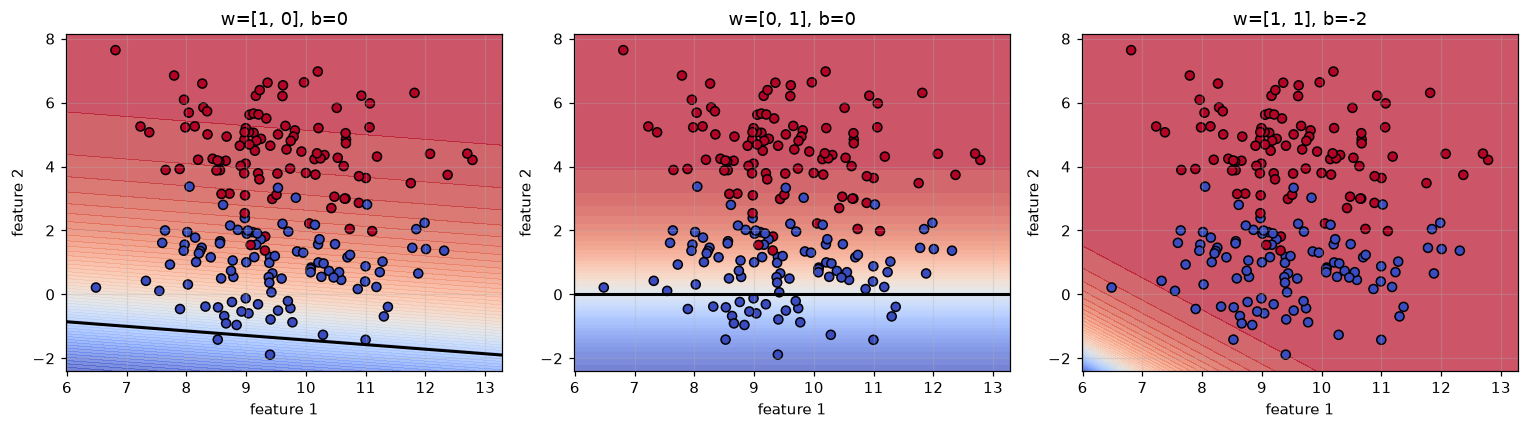

In [56]:
def neuron_predict(grid, w, b):
    """Run a batch of points through the neuron. grid: (n_points, 2)."""
    return sigmoid(grid @ w + b)


fig, axes = plt.subplots(1, 3, figsize=(14, 4))

settings = [
    (np.array([0.1, 0.7]), 0.0, "w=[1, 0], b=0"),
    (np.array([0.0, 1.0]), 0.0, "w=[0, 1], b=0"),
    (np.array([1.0, 1.0]), -2.0, "w=[1, 1], b=-2"),
]

for ax, (w_try, b_try, label) in zip(axes, settings):
    plot_decision_boundary(
        lambda g: neuron_predict(g, w_try, b_try), X, y, title=label, ax=ax
    )

plt.tight_layout()
plt.show()

---
# Part 3 — Learning by gradient descent

To make the computer find good weights, we need two things:

1. a **loss** — a single number that says how wrong the current weights are
2. a **rule** for changing the weights to make that number smaller

Then we repeat step 2 until the loss stops going down. That's training. All of it.

In [ ]:
def mse_loss(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)

def bce_loss(y_pred, y_true):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

preds = np.linspace(0.001, 0.999, 300)
truth = np.ones_like(preds)

plt.figure()
plt.plot(preds, [(p - 1.0) ** 2 for p in preds], label="MSE", linewdth=2)
plt.plot(preds, -np.log(preds), label="binary cross-entropy", linewidth=2)
plt.xlabel("predicted probability (true answer = 1)")
plt.ylabel("loss")
plt.legend()
plt.show()